# Семинар 9. Обучение и дообучение языковых моделей

На GPT-2 сравниваем генерацию базовой модели и модели после SFT, обучаем reward model и применяем DPO. Затем настраиваем LoRA, сравниваем число обучаемых параметров и выполняем короткое дообучение адаптера.

Для полного запуска выберите среду с GPU и выполняйте ячейки по порядку. Первый запуск загружает модель и данные из сети; на CPU обучение занимает значительно больше времени.

In [ ]:
%pip install -q "torch>=2.6" "transformers==5.20.2" "datasets==4.8.5" "huggingface-hub==1.33.0" "accelerate==1.15.0" "peft==0.21.2" "pyarrow==23.0.1" "fsspec[http]==2025.12.0" "matplotlib>=3.8,<4" "ipywidgets>=8.1,<9"


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
import copy
import gc
import re
import os
import random

os.environ["TOKENIZERS_PARALLELISM"] = "false"
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


## Подготовка данных

Предобученная модель - GPT-2. [Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf).

In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")

model_name = "openai-community/gpt2"
MODEL_REVISION = "607a30d783dfa663caf39e06633721c8d4cfcd7e"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=MODEL_REVISION)
tokenizer.pad_token = tokenizer.eos_token

# Для обучения causal LM удобнее right padding:
# тогда промпт, ответ и labels находятся в одних и тех же позициях.
# Left padding часто используют только для batched generation.
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(model_name, revision=MODEL_REVISION, attn_implementation="eager" if device.type == "mps" else "sdpa").to(device)
print(f"Модель: {model_name}, параметров: "
      f"{sum(p.numel() for p in model.parameters()):,}")


Device: mps


W1030 02:11:26.479000 45844 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Модель: openai-community/gpt2, параметров: 124,439,808


Рассматриваемая модель является стандартной авторегрессионной языковой моделью, обученной максимизировать правдоподобие последовательности:

$$\log P(x_1, \ldots, x_T) = \sum_{t=1}^{T} \log P(x_t \mid x_{<t}).$$

Такая постановка не предполагает наличия "задачи" в явном виде: модель обучается аппроксимировать распределение естественного языка.

Следовательно, при подаче вопроса модель не обязана давать ответ - она лишь продолжает наблюдаемую текстовую последовательность наиболее вероятным образом.

In [ ]:
def normalize_text(text):
    """Минимальная чистка текста перед токенизацией/генерацией."""
    if text is None:
        return ""
    text = str(text)
    # В preference/SFT датасетах иногда встречаются non-breaking spaces.
    # Для GPT-2 byte-level BPE это отдельные странные токены, которые потом
    # часто проявляются как пустые ответы, Â, \xa0 и длинные пробельные куски.
    text = text.replace("\xa0", " ").replace("\u202f", " ")
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


In [ ]:
def format_chat(user_msg, assistant_msg=None):
    """
    Единый шаблон чата.

    Важно: prompt заканчивается на 'Assistant:' без trailing space.
    Для GPT-2 BPE строка 'Assistant: I ...' токенизируется так, что первый
    токен ответа обычно равен ' I'. Если prompt содержит trailing space,
    этот первый токен может ошибочно попасть в prompt-mask.
    """
    user_msg = normalize_text(user_msg)
    prompt = f"User: {user_msg}\nAssistant:"

    if assistant_msg is None:
        return prompt, None

    assistant_msg = normalize_text(assistant_msg)
    full = prompt + " " + assistant_msg + tokenizer.eos_token
    return prompt, full


In [ ]:
def clean_generated_text(text):
    """Чистим артефакты byte-level GPT-2 decoding только для печати."""
    text = text.replace("\xa0", " ").replace("Â", "")
    # Не схлопываем все переносы: для кода они могут быть полезны.
    text = re.sub(r"[ \t]{2,}", " ", text)
    return text.strip()


In [ ]:
def generate_text(model, tokenizer, prompt, max_new_tokens=60,
                  min_new_tokens=0, temperature=0.7, do_sample=False):
    """
    Генерация только новых токенов.

    Для демонстрации по умолчанию используется greedy decoding: так проще
    сравнивать Base / SFT / DPO и не путать качество модели со случайностью.
    """
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    generation_kwargs = dict(
        **inputs,
        max_new_tokens=max_new_tokens,
        min_new_tokens=min_new_tokens,
        do_sample=do_sample,
        top_p=0.9 if do_sample else None,
        temperature=temperature if do_sample else None,
        repetition_penalty=1.12,
        no_repeat_ngram_size=3,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.eos_token_id,
    )
    # Убираем None, чтобы transformers не ругался на temperature/top_p при greedy.
    generation_kwargs = {k: v for k, v in generation_kwargs.items() if v is not None}

    with torch.no_grad():
        outputs = model.generate(**generation_kwargs)

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return clean_generated_text(tokenizer.decode(new_tokens, skip_special_tokens=True))


In [ ]:
test_prompts = [
    "What is the capital of France?",
    "Translate to French: Hello, how are you?",
    "Explain quantum computing in simple terms.",
    "Write a Python function to sort a list.",
    "What are the benefits of exercise?",
]

for user_msg in test_prompts:
    response = generate_text(model, tokenizer, user_msg, max_new_tokens=50)
    print(f"User: {user_msg}")
    print(f"Assistant: {response[:150]}...\n")

User: What is the capital of France?
Assistant: The French government has been in power since 1871. The country's economy grew by 2% between 1900 and 1920, but it was still a small nation with only ...



User: Translate to French: Hello, how are you?
Assistant: The first thing I did was write a short story about the events of September 11th. It's called "A New Hope." The book is based on my own experiences as...



User: Explain quantum computing in simple terms.
Assistant: The first step is to understand the nature of a system and how it works, which can be done by looking at its properties or using some other mathematic...



User: Write a Python function to sort a list.
Assistant: The following code will return the sorted result: >>> from r2 import Sort by sorting_by = True def getSort(self): """ Returns an array of all elements...



User: What are the benefits of exercise?
Assistant: The main benefit is that you can get a better feel for your body and improve it. The other side is, if there's any kind or amount of stress in life (l...



Вопрос: Почему базовая модель продолжает текст, а не отвечает на вопрос?

#### Ответ:

Базовая GPT-2 обучена предсказывать следующий токен. Поэтому продолжение вопроса тоже может быть вероятным текстом. Сам по себе шаблон `User: ... Assistant:` не обучает модель следовать инструкции.

### Формат инструкций

Будем форматировать вход как инструкцию и посмотрим на результат.

In [ ]:
example_prompt, _ = format_chat("What is the capital of France?")
print(example_prompt)

User: What is the capital of France?
Assistant:


In [ ]:
test_prompts = [
    "What is the capital of France?",
    "Translate to French: Hello, how are you?",
    "Explain quantum computing in simple terms.",
    "Write a Python function to sort a list.",
    "What are the benefits of exercise?",
]

for user_msg in test_prompts:
    prompt, _ = format_chat(user_msg)
    response = generate_text(model, tokenizer, prompt, max_new_tokens=50)
    print(f"{prompt + response[:150]}\n")

User: What is the capital of France?
Assistant:The French are known for their great wealth and they have a very strong sense of justice. They believe that if you don't do something right, then it w



User: Translate to French: Hello, how are you?
Assistant:I'm in France. You're welcome! Thank you for coming over here and taking a look at my work on the project with me today. It's been an amazing experien



User: Explain quantum computing in simple terms.
Assistant:I'm not sure what you mean by "simple". It's a very complex concept, and it has many different uses for people who are interested in the topic of this



User: Write a Python function to sort a list.
Assistant:Create an assistant for sorting the lists of items in your database using this helper method, and then call it with any other functions you want (e., 



User: What are the benefits of exercise?
Assistant:Exercise is a great way to get your body back on track. It's also an excellent source for muscle building and strength training, so you can build up m



## Supervised Fine-tuning

На этапе Supervised Fine-Tuning модель дообучается на парах «запрос - ответ».

Пусть имеется пара $(x, y)$, где $x$ - запрос (prompt), $y$ - ответ (response). Тогда оптимизируется условное правдоподобие:

$$\log P(y \mid x) = \sum_{t=1}^{|y|} \log P(y_t \mid x, y_{<t}).$$

В этой постановке функция потерь вычисляется только по токенам ответа. Модель видит всю последовательность; данные, шаблон и маска должны соответствовать друг другу.


In [ ]:
sft_dataset = load_dataset("trl-lib/Capybara", split="train", revision="e235e846458bff3398a88aed812347f7f0756520")
print(f"Всего примеров: {len(sft_dataset)}")
print(f"Колонки: {sft_dataset.column_names}")

Using the latest cached version of the dataset since trl-lib/Capybara couldn't be found on the Hugging Face Hub


Found the latest cached dataset configuration 'default' at /Users/olga/Documents/ChatGPT/DL 2/tmp/week9_seminar_mmp/hf_cache/datasets/trl-lib___capybara/default/0.0.0/e235e846458bff3398a88aed812347f7f0756520 (last modified on Thu Oct 22 22:26:33 2026).


Всего примеров: 15806
Колонки: ['source', 'messages', 'num_turns']


In [ ]:
# Посмотрим формат
sample = sft_dataset[0]

if "messages" in sample:
    print("\nПример из датасета:")
    for msg in sample["messages"][:3]:
        role = msg["role"]
        content = msg["content"][:80]
        print(f"  [{role}]: {content}...")



Пример из датасета:
  [user]: Recommend a movie to watch.
...
  [assistant]: I would recommend the movie, "The Shawshank Redemption" which is a classic drama...
  [user]: Describe the character development of Tim Robbins' character in "The Shawshank R...


In [ ]:
def format_sft_example(example):
    """
    Конвертируем messages → (prompt_text, full_text) в нашем формате чата.
    Берем первый user→assistant обмен.
    """
    messages = example["messages"]

    user_msg = None
    assistant_msg = None
    for msg in messages:
        if msg["role"] == "user" and user_msg is None:
            user_msg = msg["content"]
        elif msg["role"] == "assistant" and assistant_msg is None:
            assistant_msg = msg["content"]
        if user_msg and assistant_msg:
            break

    if not user_msg or not assistant_msg:
        return {"prompt_text": "", "full_text": ""}

    prompt_text, full_text = format_chat(user_msg, assistant_msg)
    return {"prompt_text": prompt_text, "full_text": full_text}


sft_formatted = sft_dataset.map(
    format_sft_example,
    remove_columns=sft_dataset.column_names,
    num_proc=2
)
sft_formatted = sft_formatted.filter(lambda x: len(x["full_text"]) > 0)

print(f"Отформатированных примеров: {len(sft_formatted)}")
print(f"\nПример prompt_text:\n  {repr(sft_formatted[0]['prompt_text'][:120])}")
print(f"\nПример full_text:\n  {repr(sft_formatted[0]['full_text'][:200])}")

Отформатированных примеров: 15806

Пример prompt_text:
  'User: Recommend a movie to watch.\nAssistant:'

Пример full_text:
  'User: Recommend a movie to watch.\nAssistant: I would recommend the movie, "The Shawshank Redemption" which is a classic drama film starring Tim Robbins and Morgan Freeman. This film tells a powerful s'


Реализация данной постановки осуществляется через маскирование токенов prompt.

Для токенов, принадлежащих входной части (prompt), значение target устанавливается равным -100, что исключает их из вычисления функции потерь.

Таким образом, модель получает доступ к prompt как к условию, но не оптимизирует его генерацию.

In [ ]:
MAX_LEN = 512


def encode_response_only(prompt_text, full_text, max_len=MAX_LEN):
    """
    Кодируем пару prompt/full и строим labels только по токенам ответа.

    Ключевые детали:
    1. prompt_text должен быть точным префиксом full_text;
    2. prompt НЕ содержит trailing space после 'Assistant:';
    3. первый токен ответа не должен попадать в -100;
    4. для обучения оставляем только complete-примеры, где EOS попал в окно.
    """
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    full_ids_raw = tokenizer(full_text, add_special_tokens=False)["input_ids"]

    was_truncated = len(full_ids_raw) > max_len
    full_ids = full_ids_raw[:max_len]

    # Если prompt длиннее окна, ответа в обучающей части нет.
    prompt_len = min(len(prompt_ids), len(full_ids))
    labels = [-100] * prompt_len + full_ids[prompt_len:]

    attention_mask = [1] * len(full_ids)
    pad_len = max_len - len(full_ids)
    if pad_len > 0:
        full_ids = full_ids + [tokenizer.pad_token_id] * pad_len
        attention_mask = attention_mask + [0] * pad_len
        labels = labels + [-100] * pad_len

    response_labels = [x for x in labels if x != -100]
    has_eos = tokenizer.eos_token_id in response_labels

    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "prompt_length": prompt_len,
        "n_response_tokens": len(response_labels),
        "has_eos": has_eos,
        "was_truncated": was_truncated,
    }


In [ ]:
def tokenize_sft(examples):
    features = [
        encode_response_only(prompt_text, full_text)
        for prompt_text, full_text in zip(examples["prompt_text"],
                                          examples["full_text"])
    ]
    return {key: [f[key] for f in features] for key in features[0]}


In [ ]:
# Берем больше сырых примеров, но оставляем только короткие complete-ответы.
# Это важнее, чем обучаться на обрезанных хвостах без EOS.
N_SFT_EXAMPLES = min(12000, len(sft_formatted))
sft_tokenized = sft_formatted.select(range(N_SFT_EXAMPLES))
sft_tokenized = sft_tokenized.map(
    tokenize_sft, batched=True, batch_size=64,
    remove_columns=["prompt_text", "full_text"]
)

sft_tokenized = sft_tokenized.filter(
    lambda x: 8 <= x["n_response_tokens"] <= 220 and x["has_eos"] and not x["was_truncated"]
)
sft_tokenized.set_format("torch")

print(f"Токенизированных complete-примеров после фильтра: {len(sft_tokenized)}")

# Делаем маленький validation split, чтобы смотреть не только training loss.
sft_split = sft_tokenized.train_test_split(test_size=min(512, max(1, len(sft_tokenized)//10)), seed=42)
sft_train = sft_split["train"]
sft_val = sft_split["test"]
sft_train.set_format("torch")
sft_val.set_format("torch")
print(f"SFT train: {len(sft_train)}, val: {len(sft_val)}")


Токенизированных complete-примеров после фильтра: 5130
SFT train: 4618, val: 512


In [ ]:
# Исключаем из train полные дубли валидационных примеров.
def sft_example_key(row):
    return tuple(tuple(row[k].tolist()) for k in ("input_ids", "attention_mask", "labels"))

validation_keys = {sft_example_key(row) for row in sft_val}
n_train_before_dedup = len(sft_train)
sft_train = sft_train.filter(lambda row: sft_example_key(row) not in validation_keys)
print(f"Исключено полных дублей validation из train: {n_train_before_dedup - len(sft_train)}")
print(f"После удаления дублей: train={len(sft_train)}, validation={len(sft_val)}")


Исключено полных дублей validation из train: 18
После удаления дублей: train=4600, validation=512


In [ ]:
sample_labels = sft_tokenized[2]["labels"]
sample_ids = sft_tokenized[2]["input_ids"]
n_masked = (sample_labels == -100).sum().item()
n_total = (sample_labels != -100).sum().item()
print(f"Пример: {n_masked} токенов prompt/PAD (маскированы), "
      f"{n_total} токенов ответа (обучаемые)")

Пример: 375 токенов prompt/PAD (маскированы), 137 токенов ответа (обучаемые)


In [ ]:
def visualize_sft_mask(input_ids, labels, tokenizer, max_show=50):
    """Показываем какие токены маскированы, а какие нет."""
    ids = input_ids[:max_show].tolist()
    labs = labels[:max_show].tolist()

    print("  [MASK] = prompt/PAD (loss не считается)")
    print("  [TRAIN] = ответ (loss считается)\n")

    tokens_display = []
    for token_id, label in zip(ids, labs):
        token_str = tokenizer.decode([token_id])
        status = "[MASK] " if label == -100 else "[TRAIN]"
        tokens_display.append(f"  {status} {repr(token_str)}")

    print("\n".join(tokens_display[:max_show]))
    if len(input_ids) > max_show:
        print(f"  ... не показано токенов: {len(input_ids) - max_show}")


visualize_sft_mask(sft_tokenized[0]["input_ids"],
                   sft_tokenized[0]["labels"], tokenizer, 150)


  [MASK] = prompt/PAD (loss не считается)
  [TRAIN] = ответ (loss считается)

  [MASK]  'User'
  [MASK]  ':'
  [MASK]  ' Recommend'
  [MASK]  ' a'
  [MASK]  ' movie'
  [MASK]  ' to'
  [MASK]  ' watch'
  [MASK]  '.'
  [MASK]  '\n'
  [MASK]  'Assistant'
  [MASK]  ':'
  [TRAIN] ' I'
  [TRAIN] ' would'
  [TRAIN] ' recommend'
  [TRAIN] ' the'
  [TRAIN] ' movie'
  [TRAIN] ','
  [TRAIN] ' "'
  [TRAIN] 'The'
  [TRAIN] ' Shaw'
  [TRAIN] 'sh'
  [TRAIN] 'ank'
  [TRAIN] ' Redemption'
  [TRAIN] '"'
  [TRAIN] ' which'
  [TRAIN] ' is'
  [TRAIN] ' a'
  [TRAIN] ' classic'
  [TRAIN] ' drama'
  [TRAIN] ' film'
  [TRAIN] ' starring'
  [TRAIN] ' Tim'
  [TRAIN] ' Robbins'
  [TRAIN] ' and'
  [TRAIN] ' Morgan'
  [TRAIN] ' Freeman'
  [TRAIN] '.'
  [TRAIN] ' This'
  [TRAIN] ' film'
  [TRAIN] ' tells'
  [TRAIN] ' a'
  [TRAIN] ' powerful'
  [TRAIN] ' story'
  [TRAIN] ' about'
  [TRAIN] ' hope'
  [TRAIN] ' and'
  [TRAIN] ' resilience'
  [TRAIN] ','
  [TRAIN] ' as'
  [TRAIN] ' it'
  [TRAIN] ' follows'
  [TRAIN] ' t

Данная схема обучения реализует следующую декомпозицию:

- prompt задает условное распределение;
- response определяет область оптимизации.

Иными словами, модель обучается аппроксимировать распределение ответов при фиксированном условии.

В этой функции потерь оптимизируется условное правдоподобие $P(y \mid x)$.

CLM loss учитывает все непустые позиции после сдвига, SFT loss - только ответ. Их значения усредняются по разным наборам токенов. Ни одно из них само по себе не измеряет фактическую правильность ответа.

In [ ]:
def compute_sft_loss(model, batch):
    """
    SFT loss: cross-entropy с labels=-100 для промпта.
    HuggingFace автоматически:
    1. Сдвигает logits и labels (shift)
    2. Игнорирует позиции с label=-100
    """
    return model(
        input_ids=batch["input_ids"].to(device),
        attention_mask=batch["attention_mask"].to(device),
        labels=batch["labels"].to(device),
    ).loss


def compute_clm_loss(model, batch):
    """Для сравнения: loss по ВСЕМ токенам (включая промпт)."""
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = input_ids.clone()
    labels[attention_mask == 0] = -100
    return model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels,
    ).loss


In [ ]:
# Сравниваем SFT loss и CLM loss на одном батче ДО обучения
sft_loader = DataLoader(sft_tokenized, batch_size=4, shuffle=True)
sample_batch = next(iter(sft_loader))

with torch.no_grad():
    loss_sft_before = compute_sft_loss(model, sample_batch)
    loss_clm_before = compute_clm_loss(model, sample_batch)

print(f"До обучения:")
print(f"SFT loss (только ответ): {loss_sft_before.item():.4f}")
print(f"CLM loss (вся последовательность): {loss_clm_before.item():.4f}")
print(f"Разница: {abs(loss_sft_before.item() - loss_clm_before.item()):.4f}")


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


До обучения:
SFT loss (только ответ): 2.1825
CLM loss (вся последовательность): 2.8035
Разница: 0.6210


In [ ]:
def evaluate_sft_loss(model, dataset, n_batches=30, batch_size=4):
    """Средний response-only loss на held-out примерах."""
    was_training = model.training
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    losses = []
    # DataLoader не должен менять RNG последующего обучения.
    with torch.random.fork_rng(devices=[]), torch.no_grad():
        for i, batch in enumerate(loader):
            if i >= n_batches:
                break
            losses.append(compute_sft_loss(model, batch).item())
    model.train(was_training)
    return float(np.mean(losses)) if losses else float("nan")


Для валидации фиксированы первые 80 из 512 примеров: 20 батчей по 4, среднее по loss батчей. Замеры сделаны до первого обновления, затем через 100 обновлений и после 900-го. В правой панели CLM измеряется после обновления, а SFT - перед ним на том же обучающем батче.

In [ ]:
# Освобождаем лишнюю память перед копией модели.
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

sft_model = copy.deepcopy(model)
sft_model.train()

optimizer = torch.optim.AdamW(sft_model.parameters(), lr=1e-5, weight_decay=0.01)
sft_loader = DataLoader(sft_train, batch_size=4, shuffle=True)

sft_losses = []
val_losses = []
clm_losses = []
num_steps = 900


In [ ]:
sft_val_before = evaluate_sft_loss(sft_model, sft_val, n_batches=20, batch_size=4)
val_losses.append((0, sft_val_before))
print(f"До обновлений: val SFT loss={sft_val_before:.4f}")


До обновлений: val SFT loss=2.6630


In [ ]:
step = 0
for batch in tqdm(sft_loader, total=num_steps, desc="SFT"):
    if step >= num_steps:
        break

    loss = compute_sft_loss(sft_model, batch)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(sft_model.parameters(), 1.0)
    optimizer.step()

    sft_losses.append(loss.item())

    if step % 20 == 0:
        with torch.no_grad():
            clm_l = compute_clm_loss(sft_model, batch).item()
        clm_losses.append((step + 1, clm_l))

    if (step + 1) % 100 == 0:
        val_l = evaluate_sft_loss(sft_model, sft_val, n_batches=20, batch_size=4)
        val_losses.append((step + 1, val_l))
        print(f"  Step {step + 1}: train_sft_loss={loss.item():.4f}, val_sft_loss={val_l:.4f}")

    step += 1

sft_model.eval();


  Step 100: train_sft_loss=2.5552, val_sft_loss=2.3253


  Step 200: train_sft_loss=2.4805, val_sft_loss=2.2573


  Step 300: train_sft_loss=2.6619, val_sft_loss=2.2240


  Step 400: train_sft_loss=2.1894, val_sft_loss=2.1980


  Step 500: train_sft_loss=2.2910, val_sft_loss=2.1736


  Step 600: train_sft_loss=1.9927, val_sft_loss=2.1573


  Step 700: train_sft_loss=2.9656, val_sft_loss=2.1493


  Step 800: train_sft_loss=2.7816, val_sft_loss=2.1308


  Step 900: train_sft_loss=2.5842, val_sft_loss=2.1161


In [ ]:
sft_val_after = val_losses[-1][1]
assert val_losses[0][0] == 0 and val_losses[-1][0] == len(sft_losses) == 900
print(f"Validation response-only loss: {sft_val_before:.4f} -> {sft_val_after:.4f}")


Validation response-only loss: 2.6630 -> 2.1161


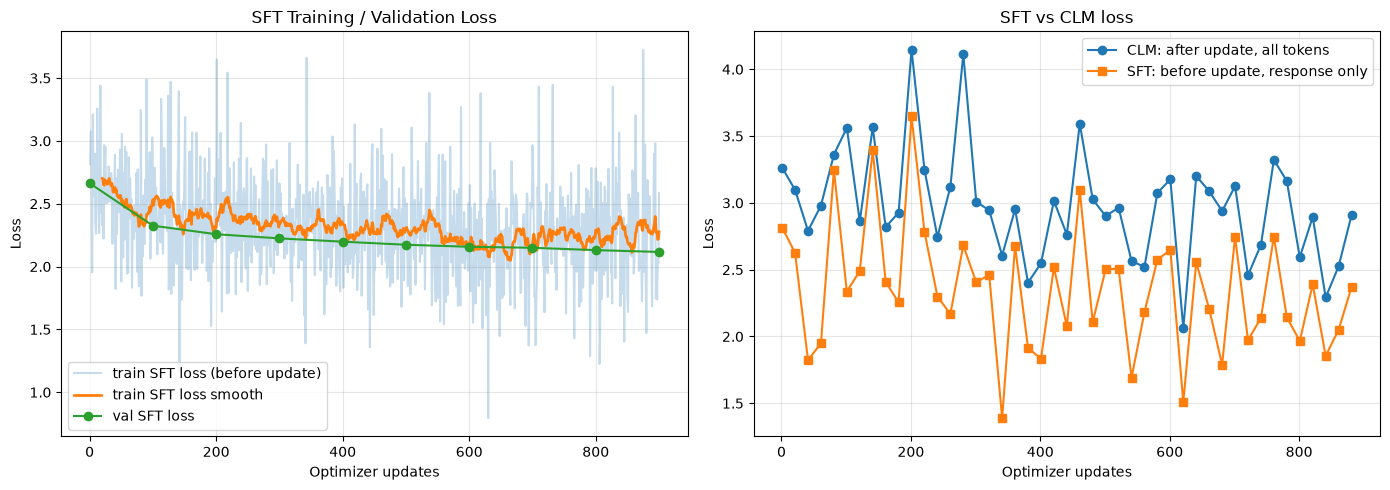

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(np.arange(1, len(sft_losses) + 1), sft_losses, alpha=0.25, label="train SFT loss (before update)")
if len(sft_losses) >= 20:
    axes[0].plot(np.arange(20, len(sft_losses) + 1), np.convolve(sft_losses, np.ones(20)/20, mode='valid'),
                 linewidth=2, label="train SFT loss smooth")
if val_losses:
    val_steps, val_vals = zip(*val_losses)
    axes[0].plot(val_steps, val_vals, 'o-', label="val SFT loss")
axes[0].set_xlabel("Optimizer updates")
axes[0].set_ylabel("Loss")
axes[0].set_title("SFT Training / Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

clm_steps, clm_vals = zip(*clm_losses)
axes[1].plot(clm_steps, clm_vals, 'o-', label="CLM: after update, all tokens")
sft_at_clm_steps = [sft_losses[s - 1] for s in clm_steps if s <= len(sft_losses)]
axes[1].plot(list(clm_steps)[:len(sft_at_clm_steps)], sft_at_clm_steps, 's-', label="SFT: before update, response only")
axes[1].set_xlabel("Optimizer updates")
axes[1].set_ylabel("Loss")
axes[1].set_title("SFT vs CLM loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


В первом сравнении обе модели получают один и тот же форматированный запрос и используют greedy decoding. Во втором меняется только формат запроса к SFT-модели; параметры генерации совпадают.

In [ ]:
for user_msg in test_prompts[:3]:
    format_user_msg = format_chat(user_msg)[0]
    resp_base = generate_text(model, tokenizer, format_user_msg,
                              max_new_tokens=50)
    resp_sft = generate_text(sft_model, tokenizer, format_user_msg,
                             max_new_tokens=50)
    print(f"User: {user_msg}")
    print(f"Base: {resp_base[:150]}")
    print(f"SFT: {resp_sft[:150]}\n")


User: What is the capital of France?
Base: The French are known for their great wealth and they have a very strong sense of justice. They believe that if you don't do something right, then it w
SFT: The French Capital, which stands for "Capital City," was established in 1789 by Louis XIV. It has been a symbol of stability and prosperity since its 



User: Translate to French: Hello, how are you?
Base: I'm in France. You're welcome! Thank you for coming over here and taking a look at my work on the project with me today. It's been an amazing experien
SFT: I'm sorry for the delay. Please feel free and let me know if there's anything else that needs clarification or clarifying before we can continue on wi



User: Explain quantum computing in simple terms.
Base: I'm not sure what you mean by "simple". It's a very complex concept, and it has many different uses for people who are interested in the topic of this
SFT: Quantum computers are computer programs that can perform computations on a single physical object, such as an atom or electron (or any other particle)



In [ ]:
raw_prompt = "What is the capital of France?"
raw_resp = generate_text(sft_model, tokenizer, raw_prompt, max_new_tokens=30, do_sample=False)
print(f"Raw prompt: {raw_prompt!r}")
print(f"Ответ: {raw_resp[:120]}\n")

formatted_prompt = format_chat(raw_prompt)[0]
formatted_resp = generate_text(sft_model, tokenizer, formatted_prompt, max_new_tokens=30, do_sample=False)
print(f"Formatted prompt: {formatted_prompt!r}")
print(f"Ответ: {formatted_resp[:120]}")


Raw prompt: 'What is the capital of France?'
Ответ: The French Capital: The City State (France)



Formatted prompt: 'User: What is the capital of France?\nAssistant:'
Ответ: The French Capital, which stands for "Capital City," was established in 1789 by Louis XIV. It has been a symbol of stabi


## Reward model

Reward model получает пару полных ответов на один запрос. Замороженный backbone GPT-2 дает признаки; обучается только линейная голова из 769 параметров. Bradley-Terry loss увеличивает разность score выбранного и отклоненного ответов.

In [ ]:
pref_dataset = load_dataset(
    "trl-lib/ultrafeedback_binarized", split="train", revision="47124cb5778f5d50de1c7676a412828f3ea7c555"
)
print(f"Preference примеров: {len(pref_dataset)}")

sample_pref = pref_dataset[0]
print(f"Колонки: {pref_dataset.column_names}")

Preference примеров: 62135
Колонки: ['chosen', 'rejected', 'score_chosen', 'score_rejected']


In [ ]:
def format_preference_pair(example):
    """
    Извлекаем prompt, chosen, rejected и форматируем в наш chat template.
    Берем последний user перед assistant; это лучше для multi-turn примеров.
    """
    chosen_messages = example["chosen"]
    rejected_messages = example["rejected"]

    prompt = ""
    chosen_response = ""
    rejected_response = ""

    for msg in chosen_messages:
        if msg["role"] == "user":
            prompt = msg["content"]
        elif msg["role"] == "assistant":
            chosen_response = msg["content"]
            break

    for msg in rejected_messages:
        if msg["role"] == "assistant":
            rejected_response = msg["content"]
            break

    if not prompt or not chosen_response or not rejected_response:
        return {
            "prompt": "",
            "prompt_text": "",
            "chosen_text": "",
            "rejected_text": "",
        }

    prompt_text, chosen_full = format_chat(prompt, chosen_response)
    _, rejected_full = format_chat(prompt, rejected_response)

    return {
        "prompt": normalize_text(prompt),
        "prompt_text": prompt_text,
        "chosen_text": chosen_full,
        "rejected_text": rejected_full,
    }


N_PREF_RAW = min(12000, len(pref_dataset))
pref_formatted = pref_dataset.select(range(N_PREF_RAW)).map(
    format_preference_pair,
    remove_columns=pref_dataset.column_names,
)
pref_formatted = pref_formatted.filter(lambda x: len(x["chosen_text"]) > 0)
print(f"Отформатированных пар: {len(pref_formatted)}")

print(f"\nПример prompt_text:\n  {repr(pref_formatted[0]['prompt_text'][:150])}")
print(f"\nПример chosen:\n  {repr(pref_formatted[0]['chosen_text'][:150])}")
print(f"\nПример rejected:\n  {repr(pref_formatted[0]['rejected_text'][:150])}")

Отформатированных пар: 11979

Пример prompt_text:
  'User: Use the pygame library to write a version of the classic game Snake, with a unique twist\nAssistant:'

Пример chosen:
  "User: Use the pygame library to write a version of the classic game Snake, with a unique twist\nAssistant: Sure, I'd be happy to help you write a versi"

Пример rejected:
  "User: Use the pygame library to write a version of the classic game Snake, with a unique twist\nAssistant: Sure, here's an example of how to write a ve"


In [ ]:
class GPT2RewardModel(torch.nn.Module):
    """
    GPT-2 backbone (замороженный) + линейная голова → скаляр.

    Это учебная RM, не полноценная production reward model. Чтобы сигнал был
    чуть стабильнее, берем mean pooling по непаддинговым токенам, а не только
    последний токен: для short/long ответов последний токен часто EOS.
    """
    def __init__(self, base_lm):
        super().__init__()
        self.backbone = copy.deepcopy(base_lm.transformer)
        hidden_size = base_lm.config.n_embd
        self.reward_head = torch.nn.Linear(hidden_size, 1)

        for param in self.backbone.parameters():
            param.requires_grad = False

    def forward(self, input_ids, attention_mask):
        outputs = self.backbone(
            input_ids=input_ids, attention_mask=attention_mask
        )
        hidden = outputs.last_hidden_state
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1.0)
        return self.reward_head(pooled).squeeze(-1)


In [ ]:
# RM обучаем поверх SFT-backbone, потому что именно SFT-модель потом сравниваем.
rm = GPT2RewardModel(sft_model).to(device)
n_trainable = sum(p.numel() for p in rm.parameters() if p.requires_grad)
print(f"\nRM: {n_trainable:,} обучаемых / "
      f"{sum(p.numel() for p in rm.parameters()):,} всего")



RM: 769 обучаемых / 124,440,577 всего


In [ ]:
def tokenize_preference(examples):
    """
    Токенизация preference-пар для RM и DPO.

    Для DPO отбрасываем обрезанные пары: если chosen/rejected не помещается
    целиком, модель получает странный сигнал по неполному ответу без EOS.
    """
    chosen_features = [
        encode_response_only(prompt_text, chosen_text)
        for prompt_text, chosen_text in zip(examples["prompt_text"],
                                            examples["chosen_text"])
    ]
    rejected_features = [
        encode_response_only(prompt_text, rejected_text)
        for prompt_text, rejected_text in zip(examples["prompt_text"],
                                              examples["rejected_text"])
    ]

    return {
        "chosen_input_ids": [f["input_ids"] for f in chosen_features],
        "chosen_attention_mask": [f["attention_mask"] for f in chosen_features],
        "chosen_labels": [f["labels"] for f in chosen_features],
        "chosen_n_response_tokens": [f["n_response_tokens"] for f in chosen_features],
        "chosen_has_eos": [f["has_eos"] for f in chosen_features],
        "chosen_was_truncated": [f["was_truncated"] for f in chosen_features],
        "rejected_input_ids": [f["input_ids"] for f in rejected_features],
        "rejected_attention_mask": [f["attention_mask"] for f in rejected_features],
        "rejected_labels": [f["labels"] for f in rejected_features],
        "rejected_n_response_tokens": [f["n_response_tokens"] for f in rejected_features],
        "rejected_has_eos": [f["has_eos"] for f in rejected_features],
        "rejected_was_truncated": [f["was_truncated"] for f in rejected_features],
    }


In [ ]:
pref_tokenized = pref_formatted.map(
    tokenize_preference, batched=True, batch_size=64,
    remove_columns=["prompt", "prompt_text", "chosen_text", "rejected_text"]
)

pref_tokenized = pref_tokenized.filter(
    lambda x: x["chosen_n_response_tokens"] >= 8 and
              x["rejected_n_response_tokens"] >= 8 and
              x["chosen_has_eos"] and x["rejected_has_eos"] and
              not x["chosen_was_truncated"] and
              not x["rejected_was_truncated"]
)
pref_tokenized.set_format("torch")
print(f"Токенизировано complete preference-пар: {len(pref_tokenized)}")


Токенизировано complete preference-пар: 5934


In [ ]:
def bradley_terry_loss(rm, batch):
    r_chosen = rm(
        batch["chosen_input_ids"].to(device),
        batch["chosen_attention_mask"].to(device)
    )
    r_rejected = rm(
        batch["rejected_input_ids"].to(device),
        batch["rejected_attention_mask"].to(device)
    )
    loss = -F.logsigmoid(r_chosen - r_rejected).mean()
    acc = (r_chosen > r_rejected).float().mean()
    return loss, acc


In [ ]:
rm_loader = DataLoader(pref_tokenized, batch_size=16, shuffle=True)
rm_opt = torch.optim.AdamW(rm.reward_head.parameters(), lr=5e-4, weight_decay=0.01)

rm_losses, rm_accs = [], []
rm_steps = 200

rm.train()
step = 0
for batch in tqdm(rm_loader, total=rm_steps, desc="RM"):
    if step >= rm_steps:
        break
    loss, acc = bradley_terry_loss(rm, batch)
    rm_opt.zero_grad(set_to_none=True)
    loss.backward()
    rm_opt.step()
    rm_losses.append(loss.item())
    rm_accs.append(acc.item())
    if step % 50 == 0:
        print(f"  Step {step}: loss={loss.item():.4f}, acc={acc.item():.4f}")
    step += 1
rm.eval();


  Step 0: loss=0.7235, acc=0.3750


  Step 50: loss=0.7187, acc=0.6250


  Step 100: loss=0.6218, acc=0.6875


  Step 150: loss=0.7157, acc=0.5000


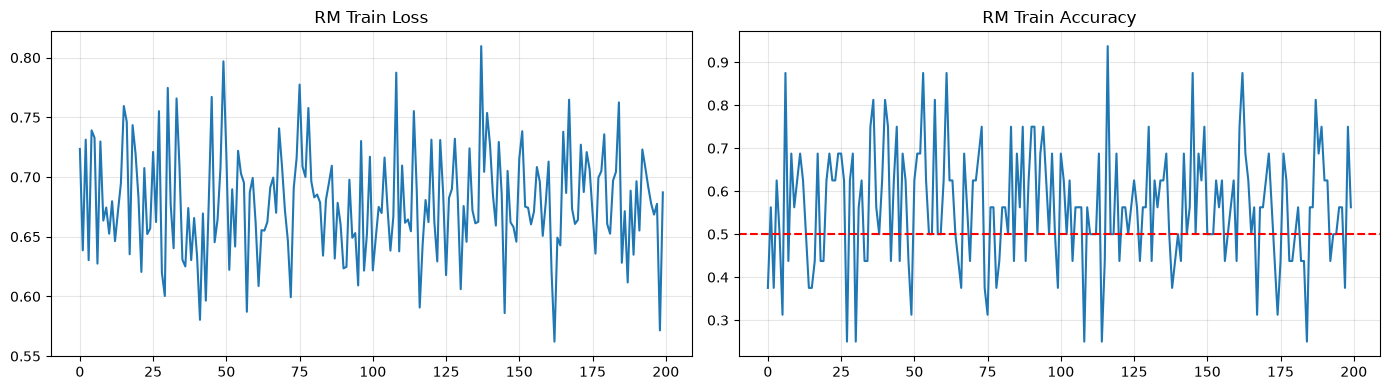

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(rm_losses); axes[0].set_title("RM Train Loss"); axes[0].grid(True, alpha=0.3)
axes[1].plot(rm_accs); axes[1].axhline(y=0.5, color='r', linestyle='--')
axes[1].set_title("RM Train Accuracy"); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Оба графика построены по обучающим батчам, отдельной проверки на отложенных парах здесь нет. Score - произвольное вещественное число, а не вероятность правильности. Модель может выше оценить фактически неверный ответ; сравнения ниже показывают и это ограничение.

In [ ]:
def score_response(rm, user_message, response, tokenizer, max_len=MAX_LEN):
    """Оценка ответа через учебную RM. Форматируем в тот же chat template."""
    _, full_text = format_chat(user_message, response)
    inputs = tokenizer(
        full_text, return_tensors="pt",
        truncation=True, max_length=max_len, padding="max_length"
    )
    with torch.no_grad():
        return rm(
            inputs["input_ids"].to(device),
            inputs["attention_mask"].to(device)
        ).item()


In [ ]:
for user_msg in test_prompts[:3]:
    prompt, _ = format_chat(user_msg)
    resp_base = generate_text(model, tokenizer, prompt, max_new_tokens=50)
    resp_sft = generate_text(sft_model, tokenizer, prompt, max_new_tokens=50)

    s_base = score_response(rm, user_msg, resp_base, tokenizer)
    s_sft = score_response(rm, user_msg, resp_sft, tokenizer)

    print(f"User: {user_msg}")
    print(f"Base:  score={s_base:+.3f} | {resp_base[:100]}")
    print(f"SFT:   score={s_sft:+.3f} | {resp_sft[:100]}\n")


User: What is the capital of France?
Base:  score=-1.331 | The French are known for their great wealth and they have a very strong sense of justice. They belie
SFT:   score=-1.124 | The French Capital, which stands for "Capital City," was established in 1789 by Louis XIV. It has be



User: Translate to French: Hello, how are you?
Base:  score=-2.150 | I'm in France. You're welcome! Thank you for coming over here and taking a look at my work on the pr
SFT:   score=-2.345 | I'm sorry for the delay. Please feel free and let me know if there's anything else that needs clarif



User: Explain quantum computing in simple terms.
Base:  score=-1.700 | I'm not sure what you mean by "simple". It's a very complex concept, and it has many different uses 
SFT:   score=-0.659 | Quantum computers are computer programs that can perform computations on a single physical object, s



## Direct Preference Optimization

SFT обучается на примерах ответов, но не использует явные парные сравнения.

Для одного запроса $x$ может существовать несколько допустимых ответов, различающихся по качеству. Поэтому вводится задача обучения на предпочтениях: в паре $(y^+, y^-)$ ответ $y^+$ отмечен как предпочтительный.


DPO использует размеченные пары напрямую. Сравнивается изменение разности log-prob выбранного и отклоненного ответов относительно фиксированной SFT reference. Reward model из предыдущего блока в этот loss не входит. В обеих DPO-копиях dropout отключен; policy сохраняет обучаемые параметры.

Direct Preference Optimization (DPO) формализует обучение на предпочтениях без явного введения reward-модели.

Пусть $\pi_\theta$ - обучаемая модель, а $\pi_{ref}$ - фиксированная reference-модель (например, после SFT).

Оптимизация направлена на увеличение относительного преимущества предпочтительного ответа по сравнению с менее предпочтительным, с учетом базового распределения.

$$
L_{DPO} =
- \log \sigma \Big(
\beta \big[
(\log \pi_\theta(y^+ \mid x) - \log \pi_\theta(y^- \mid x))
-
(\log \pi_{ref}(y^+ \mid x) - \log \pi_{ref}(y^- \mid x))
\big]
\Big).
$$

Интерпретация:

- усиливается относительная вероятность предпочтительного ответа;
- из разности log-prob вычитается та же разность для фиксированной reference-модели;
- параметр $\beta > 0$ масштабирует эту разность в функции потерь.

In [ ]:
def get_sequence_log_probs(model, input_ids, attention_mask, labels, average_log_prob=False):
    """
    log P(response | prompt) для каждого примера.

    labels=-100 для prompt/PAD. По умолчанию возвращаем сумму log-prob - это
    стандартно для DPO. average_log_prob=True полезен только для диагностики.
    """
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
    logits = outputs.logits

    # Causal LM предсказывает token[t] по logits[t-1].
    shift_logits = logits[:, :-1, :]
    shift_labels = labels[:, 1:]

    response_mask = (shift_labels != -100)
    safe_labels = shift_labels.masked_fill(~response_mask, 0)

    log_probs = F.log_softmax(shift_logits, dim=-1)
    token_log_probs = log_probs.gather(
        2, safe_labels.unsqueeze(-1)
    ).squeeze(-1)

    seq_log_probs = (token_log_probs * response_mask.float()).sum(dim=1)
    if average_log_prob:
        lengths = response_mask.float().sum(dim=1).clamp_min(1.0)
        seq_log_probs = seq_log_probs / lengths
    return seq_log_probs

In [ ]:
def compute_dpo_loss(
    policy, reference,
    chosen_ids, chosen_mask, chosen_labels,
    rejected_ids, rejected_mask, rejected_labels,
    beta=0.05,
    average_log_prob=False
):
    """
    L = -mean[ log σ( β * (Δlog π_θ - Δlog π_ref) ) ]
    """
    pi_chosen = get_sequence_log_probs(
        policy, chosen_ids, chosen_mask, chosen_labels, average_log_prob=average_log_prob)
    pi_rejected = get_sequence_log_probs(
        policy, rejected_ids, rejected_mask, rejected_labels, average_log_prob=average_log_prob)

    with torch.no_grad():
        ref_chosen = get_sequence_log_probs(
            reference, chosen_ids, chosen_mask, chosen_labels, average_log_prob=average_log_prob)
        ref_rejected = get_sequence_log_probs(
            reference, rejected_ids, rejected_mask, rejected_labels, average_log_prob=average_log_prob)

    pi_logratios = pi_chosen - pi_rejected
    ref_logratios = ref_chosen - ref_rejected
    dpo_logits = beta * (pi_logratios - ref_logratios)

    loss = -F.logsigmoid(dpo_logits).mean()

    with torch.no_grad():
        implicit_r_chosen = beta * (pi_chosen - ref_chosen)
        implicit_r_rejected = beta * (pi_rejected - ref_rejected)
        acc = (dpo_logits > 0).float().mean()
        margin = dpo_logits.mean()

    return loss, acc.item(), implicit_r_chosen.mean().item(), \
        implicit_r_rejected.mean().item(), margin.item()

In [ ]:
# Reference фиксируем как SFT-модель.
reference_model = copy.deepcopy(sft_model)
reference_model.eval()
for p in reference_model.parameters():
    p.requires_grad = False

# Policy - отдельная копия SFT. DPO не должен менять sft_model in-place.
policy_model = copy.deepcopy(sft_model)
policy_model.train()

# Сравнение policy/reference не должно содержать шум dropout.
for dpo_model in (policy_model, reference_model):
    for module in dpo_model.modules():
        if isinstance(module, torch.nn.Dropout):
            module.p = 0.0

dpo_loader = DataLoader(pref_tokenized, batch_size=2, shuffle=True)
dpo_opt = torch.optim.AdamW(policy_model.parameters(), lr=1e-6, weight_decay=0.01)

dpo_losses, dpo_accs = [], []
dpo_r_chosen, dpo_r_rejected, dpo_margins = [], [], []
dpo_steps = 300
beta = 0.05


Диагностика использует первые 16 обучающих preference-пар, зафиксированные до DPO. При одинаковых начальных весах margin равен нулю, loss равен ln(2). Accuracy при строгом сравнении margin > 0 на ничьих равна 0. Эти пары входят в обучение, поэтому итоговая таблица не оценивает обобщение.

In [ ]:
DPO_DIAGNOSTIC_PAIRS = 16
dpo_diagnostic_indices = list(range(DPO_DIAGNOSTIC_PAIRS))

def evaluate_fixed_dpo(policy, reference):
    was_training = policy.training
    policy.eval()
    values = []
    with torch.no_grad():
        for start in range(0, DPO_DIAGNOSTIC_PAIRS, 2):
            rows = [pref_tokenized[i] for i in dpo_diagnostic_indices[start:start + 2]]
            batch = {key: torch.stack([row[key] for row in rows]).to(device)
                     for key in ("chosen_input_ids", "chosen_attention_mask", "chosen_labels",
                                 "rejected_input_ids", "rejected_attention_mask", "rejected_labels")}
            loss, acc, _, _, margin = compute_dpo_loss(
                policy, reference, batch["chosen_input_ids"], batch["chosen_attention_mask"],
                batch["chosen_labels"], batch["rejected_input_ids"],
                batch["rejected_attention_mask"], batch["rejected_labels"], beta=beta)
            values.append((loss.item(), acc, margin))
    policy.train(was_training)
    loss, acc, margin = np.mean(values, axis=0)
    return dict(loss=float(loss), accuracy=float(acc), margin=float(margin))

dpo_fixed_before = evaluate_fixed_dpo(policy_model, reference_model)
assert abs(dpo_fixed_before["loss"] - np.log(2)) < 1e-6
assert abs(dpo_fixed_before["margin"]) < 1e-6
print("До DPO:", dpo_fixed_before)


До DPO: {'loss': 0.6931471824645996, 'accuracy': 0.0, 'margin': 0.0}


In [ ]:
step = 0
for batch in tqdm(dpo_loader, total=dpo_steps, desc="DPO"):
    if step >= dpo_steps:
        break

    loss, acc, rc, rr, margin = compute_dpo_loss(
        policy_model, reference_model,
        batch["chosen_input_ids"].to(device),
        batch["chosen_attention_mask"].to(device),
        batch["chosen_labels"].to(device),
        batch["rejected_input_ids"].to(device),
        batch["rejected_attention_mask"].to(device),
        batch["rejected_labels"].to(device),
        beta=beta,
    )

    dpo_opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy_model.parameters(), 1.0)
    dpo_opt.step()

    dpo_losses.append(loss.item())
    dpo_accs.append(acc)
    dpo_r_chosen.append(rc)
    dpo_r_rejected.append(rr)
    dpo_margins.append(margin)

    if step % 50 == 0:
        print(f"  Step {step}: loss={loss.item():.4f}, acc={acc:.4f}, margin={margin:+.4f}")
    step += 1

policy_model.eval();


  Step 0: loss=0.6931, acc=0.0000, margin=+0.0000


  Step 50: loss=0.6893, acc=1.0000, margin=+0.0078


  Step 100: loss=0.6887, acc=1.0000, margin=+0.0089


  Step 150: loss=0.6392, acc=1.0000, margin=+0.1134


  Step 200: loss=0.6927, acc=1.0000, margin=+0.0008


  Step 250: loss=0.7111, acc=0.0000, margin=-0.0354


In [ ]:
dpo_fixed_after = evaluate_fixed_dpo(policy_model, reference_model)
print("Первые 16 train-пар; одинаковые примеры до и после DPO")
print(f"{'Состояние':<18} {'Loss':>10} {'Accuracy':>10} {'Margin':>12}")
for name, result in [("До DPO", dpo_fixed_before), ("После 300 шагов", dpo_fixed_after)]:
    print(f"{name:<18} {result['loss']:>10.6f} {result['accuracy']:>10.4f} {result['margin']:>+12.6f}")


Первые 16 train-пар; одинаковые примеры до и после DPO
Состояние                Loss   Accuracy       Margin
До DPO               0.693147     0.0000    +0.000000
После 300 шагов      0.695723     0.6250    -0.001122


In [ ]:
def smooth_curve(x, w=20):
    if len(x) < w:
        return np.asarray(x)
    return np.convolve(x, np.ones(w) / w, mode="valid")


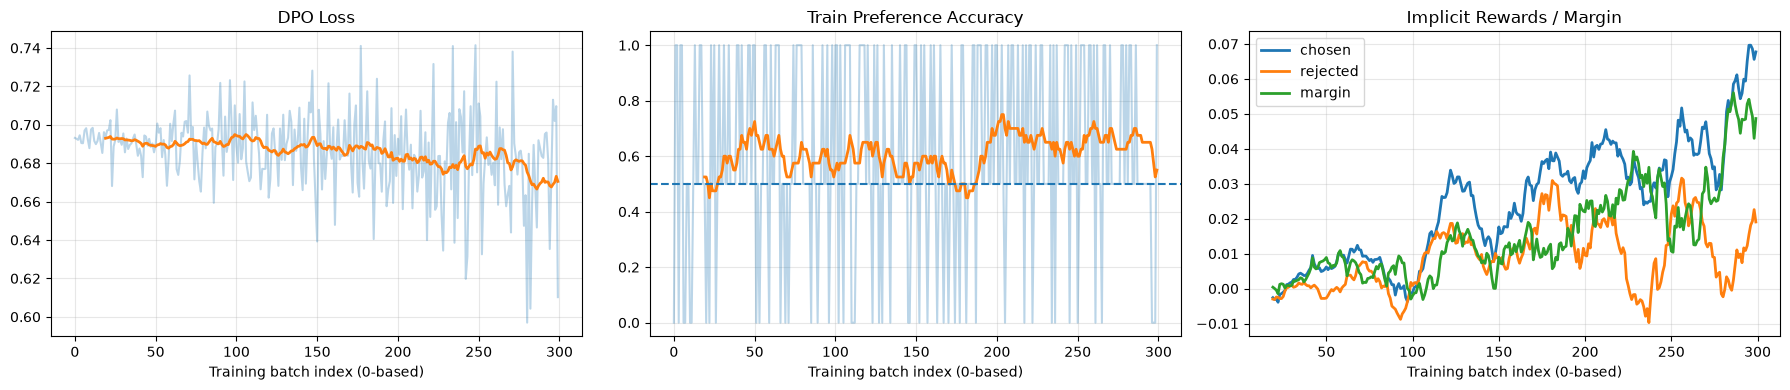

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(dpo_losses, alpha=0.3)
axes[0].plot(np.arange(19, len(dpo_losses)), smooth_curve(dpo_losses), linewidth=2)
axes[0].set_title("DPO Loss"); axes[0].grid(True, alpha=0.3)

axes[1].plot(dpo_accs, alpha=0.3)
axes[1].plot(np.arange(19, len(dpo_accs)), smooth_curve(dpo_accs), linewidth=2)
axes[1].axhline(y=0.5, linestyle="--")
axes[1].set_title("Train Preference Accuracy"); axes[1].grid(True, alpha=0.3)

axes[2].plot(np.arange(19, len(dpo_r_chosen)), smooth_curve(dpo_r_chosen), label="chosen", linewidth=2)
axes[2].plot(np.arange(19, len(dpo_r_rejected)), smooth_curve(dpo_r_rejected), label="rejected", linewidth=2)
axes[2].plot(np.arange(19, len(dpo_margins)), smooth_curve(dpo_margins), label="margin", linewidth=2)
axes[2].set_title("Implicit Rewards / Margin"); axes[2].legend()
axes[2].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xlabel("Training batch index (0-based)")

plt.tight_layout()
plt.show()


Ключевая идея DPO заключается в том, что модель обучается не абсолютной оценке качества ответа, а сравнению пар ответов.

Отдельная reward-модель не обучается: функция потерь напрямую использует вероятности ответов политики и фиксированной reference-модели.

## Сравнение моделей

На графиках меняются обучающие батчи. Для сравнения до/после используем фиксированные пары из таблицы. В генерациях Base, SFT и DPO получают одинаковый запрос и параметры greedy decoding. Небольшое изменение вероятностей может не изменить наиболее вероятный токен и весь сгенерированный ответ.

In [ ]:
all_models = {
    "Base": model,
    "SFT": sft_model,
    "SFT+DPO": policy_model,
}

for user_msg in test_prompts:
    prompt, _ = format_chat(user_msg)
    print(f"\n{'='*70}")
    print(f"User: {user_msg}")
    print(f"{'='*70}")
    for name, m in all_models.items():
        resp = generate_text(m, tokenizer, prompt, max_new_tokens=80, min_new_tokens=12, do_sample=False)
        score = score_response(rm, user_msg, resp, tokenizer)
        print(f"\n  [{name}] (учебная RM score: {score:+.3f})")
        print(f"  {resp[:300]}")


User: What is the capital of France?



  [Base] (учебная RM score: -1.375)
  The French are known for their great wealth and they have a very strong sense of justice. They believe that if you don't do something right, then it will be punished by death or imprisonment in prison (in some cases). In other words…they think there's no way to get rid from this situation any more t



  [SFT] (учебная RM score: -1.124)
  The French Capital, which stands for "Capital City," was established in 1789 by Louis XIV. It has been a symbol of stability and prosperity since its establishment as an official residence during his reign (1793-1804).



  [SFT+DPO] (учебная RM score: -1.348)
  The French Capital is a city located in Paris, which has been under British rule since 1789. It was founded by Charles II and became part-owner of its banks during his reign (1793–1804).

User: Translate to French: Hello, how are you?



  [Base] (учебная RM score: -2.057)
  I'm in France. You're welcome! Thank you for coming over here and taking a look at my work on the project with me today. It's been an amazing experience working alongside your team of translators who have helped us translate many different languages into English so far this year as well as helping o



  [SFT] (учебная RM score: -2.345)
  I'm sorry for the delay. Please feel free and let me know if there's anything else that needs clarification or clarifying before we can continue on with our journey together.


... (6 outputs left out)


  [SFT+DPO] (учебная RM score: -1.209)
  def sorted(list): return [] for i in range(len(list)) do if len(list) > 0 and not (i == 1): print("%s", i + "") else: print ("%s" % (i - 1)) end

User: What are the benefits of exercise?



  [Base] (учебная RM score: -0.998)
  Exercise is a great way to get your body back on track. It's also an excellent source for muscle building and strength training, so you can build up more muscles in just one sitting!



  [SFT] (учебная RM score: -0.748)
  Exercise can help you improve your overall health and well-being. It helps reduce stress, anxiety, depression, fatigue, insomnia, muscle soreness, headaches, nausea, vomiting, constipation or diarrhea.



  [SFT+DPO] (учебная RM score: -0.798)
  Exercise can help you improve your overall health and well-being. It helps reduce stress, anxiety, depression, fatigue, insomnia, muscle soreness, pain, inflammation, arthritis, heart disease or any other chronic condition that affects physical activity.


In [ ]:
def compare_next_token(model_a, model_b, user_msg, name_a="SFT", name_b="SFT+DPO", top_k=10):
    """Сравниваем top-k next-token predictions в формате чата."""
    prompt, _ = format_chat(user_msg)
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        logits_a = model_a(**inputs).logits[0, -1, :]
        logits_b = model_b(**inputs).logits[0, -1, :]

    probs_a = F.softmax(logits_a, dim=-1)
    probs_b = F.softmax(logits_b, dim=-1)

    all_top = set(
        torch.topk(probs_a, top_k).indices.tolist() +
        torch.topk(probs_b, top_k).indices.tolist()
    )

    token_data = [(t, probs_a[t].item(), probs_b[t].item()) for t in all_top]
    token_data.sort(key=lambda x: abs(x[2] - x[1]), reverse=True)

    print(f"\nUser: {user_msg}")
    print(f"  {'Token':<18} {name_a:<10} {name_b:<10} {'Δ':<10}")
    print("  " + "-" * 52)
    for t, pa, pb in token_data[:top_k]:
        token_str = tokenizer.decode([t]).replace("\xa0", "\\xa0")
        diff = pb - pa
        sign = "+" if diff > 0 else ""
        print(f"  {repr(token_str):<18} {pa:<10.4f} {pb:<10.4f} "
              f"{sign}{diff:<10.4f}")


In [ ]:
compare_next_token(sft_model, policy_model,
                   "What is the capital of France?")
compare_next_token(sft_model, policy_model,
                   "Explain quantum computing in simple terms.")



User: What is the capital of France?
  Token              SFT        SFT+DPO    Δ         
  ----------------------------------------------------
  ' The'             0.6275     0.6487     +0.0212    
  ' Capital'         0.0752     0.0830     +0.0078    
  ' It'              0.0337     0.0308     -0.0029   
  ' I'               0.0055     0.0037     -0.0018   
  ' France'          0.0576     0.0561     -0.0014   
  ' To'              0.0121     0.0107     -0.0014   
  ' In'              0.0215     0.0203     -0.0012   
  ' Paris'           0.0069     0.0059     -0.0010   
  ' First'           0.0052     0.0043     -0.0009   
  ' A'               0.0062     0.0058     -0.0004   

User: Explain quantum computing in simple terms.
  Token              SFT        SFT+DPO    Δ         
  ----------------------------------------------------
  ' Quantum'         0.7011     0.7467     +0.0457    
  ' The'             0.0442     0.0392     -0.0049   
  ' Let'             0.0152     0.0111     

In [ ]:
def estimate_policy_shift(policy, reference, dataloader, n_batches=20):
    """
    Это не настоящий KL. Это средний сдвиг log-prob на chosen-ответах:
    log πθ(y+|x) - log πref(y+|x).
    Отрицательное значение возможно и не является ошибкой.
    """
    values = []
    for i, batch in enumerate(dataloader):
        if i >= n_batches:
            break
        ids = batch["chosen_input_ids"].to(device)
        mask = batch["chosen_attention_mask"].to(device)
        labels = batch["chosen_labels"].to(device)
        with torch.no_grad():
            pi_lp = get_sequence_log_probs(policy, ids, mask, labels)
            ref_lp = get_sequence_log_probs(reference, ids, mask, labels)
        values.extend((pi_lp - ref_lp).cpu().tolist())
    return np.mean(values), np.std(values)


In [ ]:
shift_m, shift_s = estimate_policy_shift(policy_model, reference_model, dpo_loader)
print(f"Mean log-prob shift on chosen responses: {shift_m:.4f} ± {shift_s:.4f}")


Mean log-prob shift on chosen responses: 1.6029 ± 1.6585


## LoRA

### Классический LoRA (Low-Rank Adaptation)

**LoRA** - метод PEFT. Обновления весов представлены произведением двух матриц низкого ранга:

$$W + \Delta W = W + \frac{\alpha}{r}BA$$

где $B \in \mathbb{R}^{d \times r}$ и $A \in \mathbb{R}^{r \times k}$, и $r \ll \min(d, k)$.

Во время обучения обновляются только матрицы A и B, а исходные веса W остаются замороженными.


Множитель $\alpha/r$ задается параметрами `lora_alpha` и `r`. При стандартной инициализации PEFT матрица $B$ нулевая, поэтому новый адаптер сначала не меняет выход модели.


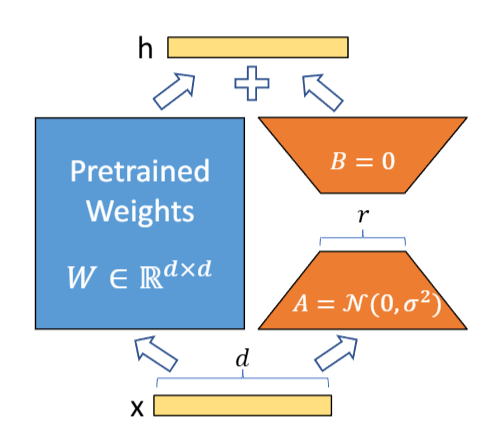

LoRA: схема малорангового адаптера. Синий - замороженные параметры, оранжевый - обучаемые  | [Источник](https://arxiv.org/abs/2106.09685)

**Вопрос:** Почему нельзя оптимизировать матрицу $\Delta W = BA$ напрямую, как единый параметр размера $d \times k$?

#### Ответ:

Прямая оптимизация полной матрицы $\Delta W$ потребовала бы $dk$ обучаемых параметров и фактически вернула бы нас к обычному дообучению соответствующего линейного слоя. Разложение $\Delta W = BA$ ограничивает ранг поправки и требует только $r(d+k)$ обучаемых параметров при $r \ll \min(d,k)$.

### Детали реализации

In [ ]:
import torch
from transformers import (AutoModelForCausalLM, AutoTokenizer, TrainingArguments, Trainer, DataCollatorForLanguageModeling)
from peft import LoraConfig, get_peft_model, TaskType
from datasets import load_dataset
import os


In [ ]:
DEVICE = str(device)
PEFT_DEMO_MAX_STEPS = 10
DATASET_NUM_PROC = max(1, min(4, os.cpu_count() or 1))

def ensure_padding_token(tokenizer, model=None):
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    if model is not None:
        model.config.pad_token_id = tokenizer.pad_token_id
        if getattr(model, "generation_config", None) is not None:
            model.generation_config.pad_token_id = tokenizer.pad_token_id
    return tokenizer, model



In [ ]:
# Пример 1: Базовый LoRA для текстовой генерации

model_name = "openai-community/gpt2"  # Используем небольшую модель для демонстрации
lora_tokenizer = AutoTokenizer.from_pretrained(model_name, revision=MODEL_REVISION)
lora_base_model = AutoModelForCausalLM.from_pretrained(model_name, revision=MODEL_REVISION, attn_implementation="eager" if device.type == "mps" else "sdpa")

# Добавляем pad_token, если его нет
lora_tokenizer, lora_base_model = ensure_padding_token(lora_tokenizer, lora_base_model)

# Настройка LoRA
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,  # Тип задачи
    r=8,                           # Ранг разложения (rank)
    lora_alpha=16,                 # Параметр масштабирования
    lora_dropout=0.1,              # Dropout для LoRA слоев
    target_modules=["c_attn"],     # Модули, к которым применяется LoRA
    fan_in_fan_out=True,           # GPT-2 Conv1D хранит веса как (fan_in, fan_out)
    bias="none",                   # Не обучаем bias
)

# Применяем LoRA к модели
peft_model = get_peft_model(lora_base_model, lora_config)

# Посмотрим, сколько параметров обучается
peft_model.print_trainable_parameters()


trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364


### LoRA с несколькими целевыми модулями

In [ ]:
# Пример 2: LoRA для attention и MLP слоев

model_name = "openai-community/gpt2"
lora_tokenizer = AutoTokenizer.from_pretrained(model_name, revision=MODEL_REVISION)
lora_base_model = AutoModelForCausalLM.from_pretrained(model_name, revision=MODEL_REVISION, attn_implementation="eager" if device.type == "mps" else "sdpa")

lora_tokenizer, lora_base_model = ensure_padding_token(lora_tokenizer, lora_base_model)

# Расширенная конфигурация LoRA
lora_config_extended = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,                          # Ранг разложения
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["c_attn", "c_proj", "c_fc"],  # Attention и MLP слои
    fan_in_fan_out=True,           # GPT-2 Conv1D хранит веса как (fan_in, fan_out)
    bias="none",
    modules_to_save=None,          # Дополнительные модули для сохранения
)

peft_model_extended = get_peft_model(lora_base_model, lora_config_extended)
peft_model_extended.print_trainable_parameters()


trainable params: 2,359,296 || all params: 126,799,104 || trainable%: 1.8607


Конфигурации различаются рангом, целевыми модулями, alpha и dropout. Сравнение показывает число обучаемых параметров, а не влияние одного только ранга и не качество. Далее обучается только первая модель: r=8, c_attn; расширенная r=16 остается без обучения.

На одном исходном промпте проверяем активный и отключенный адаптер в режиме eval. Нулевое начальное обновление должно давать одинаковые logits. Хеш замороженных весов и копия параметров адаптера нужны для проверки того, какие веса изменились за 10 шагов.

In [ ]:
import hashlib
from contextlib import nullcontext

lora_probe_prompt = "The future of AI is"

def frozen_base_digest(model):
    digest = hashlib.sha256()
    for name, parameter in model.named_parameters():
        if "lora_" not in name:
            digest.update(name.encode())
            digest.update(parameter.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

def lora_next_logits(model, adapter_enabled=True):
    was_training = model.training
    model.eval()
    inputs = lora_tokenizer(lora_probe_prompt, return_tensors="pt").to(next(model.parameters()).device)
    context = nullcontext() if adapter_enabled else model.disable_adapter()
    with context, torch.no_grad():
        logits = model(**inputs).logits[0, -1].detach().cpu()
    model.train(was_training)
    return logits

lora_base_hash_before = frozen_base_digest(peft_model)
lora_parameters_before = {name: parameter.detach().cpu().clone()
                          for name, parameter in peft_model.named_parameters() if "lora_" in name}
lora_logits_initial_on = lora_next_logits(peft_model)
lora_logits_initial_off = lora_next_logits(peft_model, adapter_enabled=False)
lora_initial_max_diff = (lora_logits_initial_on - lora_logits_initial_off).abs().max().item()
assert lora_initial_max_diff < 1e-6
print(f"До обучения: max |logits(adapter on) - logits(adapter off)| = {lora_initial_max_diff:.8f}")


До обучения: max |logits(adapter on) - logits(adapter off)| = 0.00000000


### Дообучение модели на датасете

In [ ]:
# Загружаем небольшой датасет для демонстрации
dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train[:1%]", revision="b08601e04326c79dfdd32d625aee71d232d685c3")

lora_raw_rows = len(dataset)
dataset = dataset.filter(lambda example: bool(example["text"].strip()))
print(f"WikiText train[:1%]: {lora_raw_rows} строк, исключено пустых: {lora_raw_rows - len(dataset)}, осталось: {len(dataset)}")

# Функция для токенизации
def tokenize_function(examples):
    return lora_tokenizer(
        examples["text"],
        truncation=True,
        max_length=128,
        padding="max_length"
    )

# Токенизируем данные
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=dataset.column_names,
    num_proc=DATASET_NUM_PROC,
)

# Создаем collator для language modeling
data_collator = DataCollatorForLanguageModeling(
    tokenizer=lora_tokenizer,
    mlm=False,  # Для causal LM используем False
)


WikiText train[:1%]: 367 строк, исключено пустых: 109, осталось: 258


In [ ]:
# Проверяем наличие target-токенов после causal shift в каждом примере.
# Тогда любой непустой батч имеет корректно определенный loss.
lora_target_counts = []
for i in range(len(tokenized_dataset)):
    checked_batch = data_collator([tokenized_dataset[i]])
    lora_target_counts.append(int((checked_batch["labels"][0, 1:] != -100).sum()))
assert min(lora_target_counts) > 0
print(f"Target-токенов на пример: min={min(lora_target_counts)}, max={max(lora_target_counts)}")


Target-токенов на пример: min=4, max=127


In [ ]:
# Настройка обучения (короткий demo-run, чтобы ноутбук выполнялся целиком)
training_args = TrainingArguments(
    output_dir="./lora_gpt2_output",
    num_train_epochs=1,
    max_steps=PEFT_DEMO_MAX_STEPS,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=2,
    logging_steps=1,
    save_strategy="no",
    fp16=(DEVICE == "cuda" and not torch.cuda.is_bf16_supported()),
    bf16=(DEVICE == "cuda" and torch.cuda.is_bf16_supported()),
    push_to_hub=False,
    report_to="none",
)

# Создаем trainer
trainer = Trainer(
    model=peft_model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)


In [ ]:
# Запускаем обучение
trainer.train()

# Сохраняем адаптер
peft_model.save_pretrained("./lora_gpt2_adapter")


/Users/olga/Documents/ChatGPT/DL 2/tmp/week9_seminar_mmp/env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,4.407516
2,4.945898
3,4.677670
4,4.266786
5,4.525350
6,4.728949
7,4.499161
8,4.099855
9,4.430871
10,4.857237


In [ ]:
lora_base_hash_after = frozen_base_digest(peft_model)
lora_base_unchanged = lora_base_hash_before == lora_base_hash_after
lora_changed_tensors = sum(not torch.equal(lora_parameters_before[name], parameter.detach().cpu())
                          for name, parameter in peft_model.named_parameters() if "lora_" in name)
lora_logits_trained_on = lora_next_logits(peft_model)
lora_logits_trained_off = lora_next_logits(peft_model, adapter_enabled=False)
lora_trained_max_diff = (lora_logits_trained_on - lora_logits_trained_off).abs().max().item()
assert lora_base_unchanged and lora_changed_tensors > 0 and lora_trained_max_diff > 0
print(f"{'Проверка':<42} {'Результат':>14}")
for label, result in [("Замороженная база не изменилась", lora_base_unchanged),
                      ("Изменилось LoRA-тензоров", lora_changed_tensors),
                      ("Max разность logits до обучения", f"{lora_initial_max_diff:.8f}"),
                      ("Max разность logits после обучения", f"{lora_trained_max_diff:.8f}")]:
    print(f"{label:<42} {str(result):>14}")


Проверка                                        Результат
Замороженная база не изменилась                      True
Изменилось LoRA-тензоров                               24
Max разность logits до обучения                0.00000000
Max разность logits после обучения             0.02880859


In [ ]:
peft_model.eval()
lora_probe_inputs = lora_tokenizer(lora_probe_prompt, return_tensors="pt").to(next(peft_model.parameters()).device)
lora_greedy_outputs = {}
for enabled, label in [(False, "Adapter off"), (True, "Adapter on")]:
    context = nullcontext() if enabled else peft_model.disable_adapter()
    with context, torch.no_grad():
        generated = peft_model.generate(**lora_probe_inputs, max_new_tokens=35, do_sample=False,
                                        pad_token_id=lora_tokenizer.pad_token_id)
    text = lora_tokenizer.decode(generated[0], skip_special_tokens=True)
    lora_greedy_outputs[label] = text
    print(f"{label}: {text}\n")

prob_off = lora_logits_trained_off.softmax(-1)
prob_on = lora_logits_trained_on.softmax(-1)
changed_tokens = (prob_on - prob_off).abs().topk(5).indices.tolist()
print("Топ-5 изменений вероятности следующего токена на этом же промпте")
print(f"{'Токен':<20} {'Adapter off':>12} {'Adapter on':>12} {'Разность':>12}")
for token_id in changed_tokens:
    label = repr(lora_tokenizer.decode([token_id]))
    print(f"{label:<20} {prob_off[token_id]:>12.7f} {prob_on[token_id]:>12.7f} {(prob_on[token_id] - prob_off[token_id]):>+12.7f}")


Adapter off: The future of AI is uncertain. The future of AI is uncertain.

The future of AI is uncertain. The future of AI is uncertain.

The future of AI is uncertain. The



Adapter on: The future of AI is uncertain. The future of AI is uncertain.

The future of AI is uncertain. The future of AI is uncertain.

The future of AI is uncertain. The

Топ-5 изменений вероятности следующего токена на этом же промпте
Токен                 Adapter off   Adapter on     Разность
' in'                   0.0586144    0.0584820   -0.0001324
' a'                    0.0403425    0.0402456   -0.0000969
' very'                 0.0190133    0.0189598   -0.0000535
' unclear'              0.0182185    0.0182714   +0.0000528
' still'                0.0364359    0.0364731   +0.0000372


Ненулевая разность logits показывает работу адаптера. Совпадение greedy-текстов при этом возможно. Десять шагов - демонстрация механизма обновления весов; этого запуска недостаточно для вывода об улучшении качества. Ниже сохранена исходная sampling-генерация; ее нельзя напрямую сравнивать с greedy как эффект адаптера.

In [ ]:
# Тестирование модели
def generate_lora_text(model, tokenizer, prompt, max_new_tokens=100):
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt")
    model_device = next(model.parameters()).device
    inputs = {k: v.to(model_device) for k, v in inputs.items()}
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        num_return_sequences=1,
        temperature=0.7,
        do_sample=True,
        pad_token_id=tokenizer.pad_token_id,
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Пример генерации
prompt = "The future of AI is"
print(generate_lora_text(peft_model, lora_tokenizer, prompt))

The future of AI is already in doubt. The AI revolution is already in its early stages, and there are no clear answers. The technology has already shown a pattern of adoption and is already taking off, and the future of AI is already in doubt. The technology has already shown a pattern of adoption and is already taking off, and the future of AI is already in doubt.

The problem is that the current technology has only just begun to gain steam and the future of AI will be in doubt by the time it


## Литература

- [Radford et al., Language Models are Unsupervised Multitask Learners, 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf).
- [Ouyang et al., Training language models to follow instructions with human feedback, 2022](https://arxiv.org/abs/2203.02155).
- [Christiano et al., Deep Reinforcement Learning from Human Preferences, 2017](https://arxiv.org/abs/1706.03741).
- [Rafailov et al., Direct Preference Optimization, 2023](https://arxiv.org/abs/2305.18290).
- [Hu et al., LoRA: Low-Rank Adaptation of Large Language Models, 2021](https://arxiv.org/abs/2106.09685).


[Исходный материал](https://github.com/mmp-practicum-team/mmp_dl_spring_2025)
